# Exploración visual de patrones demográficos para validaciones en captación censal

**Aguascalientes · Censo de Población y Vivienda 2020 · Cuestionario Ampliado**

## Pregunta de análisis

**¿Qué patrones y combinaciones se observan entre variables demográficas y de captación como edad, discapacidad, escolaridad, fecundidad y ubicación geográfica, y cuáles podrían resultar relevantes para el diseño de validaciones de universo, consistencia o contexto en aplicaciones de captación censal?**

Este notebook documenta de forma reproducible el procesamiento utilizado para reconstruir y ampliar las visualizaciones seleccionadas del análisis exploratorio.

> **Principio de análisis:** una combinación poco frecuente no necesariamente constituye un error. Puede representar una inconsistencia, un caso que requiere confirmación o un valor atípico válido.


## 1. Estructura del proyecto y fuentes

El proyecto utiliza rutas relativas para facilitar su ejecución en otro equipo.

```text
Proyecto_Visualizacion_Censo2020/
codigo/
    generar_visualizaciones.py
    analisis_visualizacion_censo2020.ipynb
datos/
    Personas01.CSV
    01_aguascalientes.zip
    indicador_municipal.csv
tableau/
     visualizaciones/
index.html
```

**Fuente principal:** INEGI, Censo de Población y Vivienda 2020, microdatos del Cuestionario Ampliado para Aguascalientes.

Para el análisis territorial se utiliza además la cartografía municipal del Marco Geoestadístico de INEGI.


## 2. Bibliotecas y configuración

Se utilizan **pandas** para preparación de datos, **Matplotlib** para la visualización estática, **Plotly** para las visualizaciones interactivas y **GeoPandas** para la integración territorial.


In [88]:
from pathlib import Path
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.io as pio
pio.renderers.default = "iframe"
import geopandas as gpd

BASE_DIR = Path.cwd()
if BASE_DIR.name.lower() == "codigo":
    BASE_DIR = BASE_DIR.parent

ARCHIVO_DATOS = BASE_DIR / "datos" / "Personas01.CSV"
ARCHIVO_GEO = BASE_DIR / "datos" / "01_aguascalientes.zip"
CARPETA_SALIDA = BASE_DIR / "visualizaciones"
CARPETA_SALIDA.mkdir(exist_ok=True)

print("Raíz del proyecto:", BASE_DIR)


Raíz del proyecto: C:\Users\ariana.moreno\Desktop\Proyecto_Visualizacion_Censo2020


## 3. Carga de datos

Se cargan los microdatos de personas. `low_memory=False` evita la inferencia fragmentada de tipos en un archivo de gran tamaño.


In [89]:
df = pd.read_csv(ARCHIVO_DATOS, low_memory=False)
print(f"Registros: {len(df):,}")
print(f"Variables: {df.shape[1]:,}")
df.head()


Registros: 95,983
Variables: 91


,ENT,MUN,LOC50K,ID_VIV,ID_PERSONA,COBERTURA,ESTRATO,UPM,FACTOR,CLAVIVP,...,HIJOS_SOBREVIV,FECHA_NAC_M,FECHA_NAC_A,SOBREVIVENCIA,IDENT_HIJO,EDAD_MORIR_D,EDAD_MORIR_M,EDAD_MORIR_A,EDAD_MORIR_TD,TAMLOC
0,1,1,1,10010000001,1001000000100001,2,01-001-0001-00,1,59,1,...,2.0,9.0,2001.0,1.0,3.0,NaN,NaN,NaN,NaN,5
1,1,1,1,10010000001,1001000000100002,2,01-001-0001-00,1,59,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
2,1,1,1,10010000001,1001000000100003,2,01-001-0001-00,1,59,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
3,1,1,1,10010000002,1001000000200001,2,01-001-0001-00,1,59,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
4,1,1,1,10010000002,1001000000200002,2,01-001-0001-00,1,59,1,...,2.0,5.0,2009.0,1.0,4.0,NaN,NaN,NaN,NaN,5


## 4. Preparación y limpieza

Los valores que no pueden convertirse a número se transforman en `NaN`. Los filtros específicos se documentan en cada análisis.


In [90]:
for columna in ["SEXO", "EDAD", "HIJOS_NAC_VIVOS"]:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

df[["SEXO", "EDAD", "HIJOS_NAC_VIVOS"]].describe()


,SEXO,EDAD,HIJOS_NAC_VIVOS
count,95983.000000,95983.000000,37789.000000
mean,2.023077,29.075576,2.354627
std,0.999739,20.568849,2.787149
min,1.000000,0.000000,0.000000
25%,1.000000,12.000000,0.000000
50%,3.000000,25.000000,2.000000
75%,3.000000,43.000000,3.000000
max,3.000000,104.000000,98.000000


# 5. Fecundidad por edad

Se analiza la proporción de mujeres de **12 a 20 años** que registran al menos un hijo nacido vivo. Se consideran `SEXO = 3`, edades de 12 a 20 y valores de `HIJOS_NAC_VIVOS` entre 0 y 25.

El porcentaje corresponde a la **muestra analizada** y no se presenta como una estimación poblacional ponderada.


In [91]:
fec = df[
    (df["SEXO"] == 3) &
    (df["EDAD"].between(12, 20)) &
    (df["HIJOS_NAC_VIVOS"].between(0, 25))
].copy()

fec["CON_HIJO"] = (fec["HIJOS_NAC_VIVOS"] >= 1).astype(int)

tabla_fec = (
    fec.groupby("EDAD")["CON_HIJO"]
       .agg(TOTAL_MUJERES="count", MUJERES_CON_HIJO="sum")
       .reset_index()
)

tabla_fec["PORCENTAJE"] = tabla_fec["MUJERES_CON_HIJO"] / tabla_fec["TOTAL_MUJERES"] * 100
tabla_fec


,EDAD,TOTAL_MUJERES,MUJERES_CON_HIJO,PORCENTAJE
0,12,939,0,0.000000
1,13,877,2,0.228050
2,14,907,3,0.330761
3,15,917,13,1.417666
4,16,918,40,4.357298
5,17,1025,105,10.243902
6,18,1016,197,19.389764
7,19,922,284,30.802603
8,20,930,329,35.376344


### 5.1 Visualización estática mejorada

Se incorporan etiquetas directas, jerarquía visual, una paleta monocromática y reducción de elementos innecesarios. La nota metodológica permite interpretar la gráfica de manera autónoma.


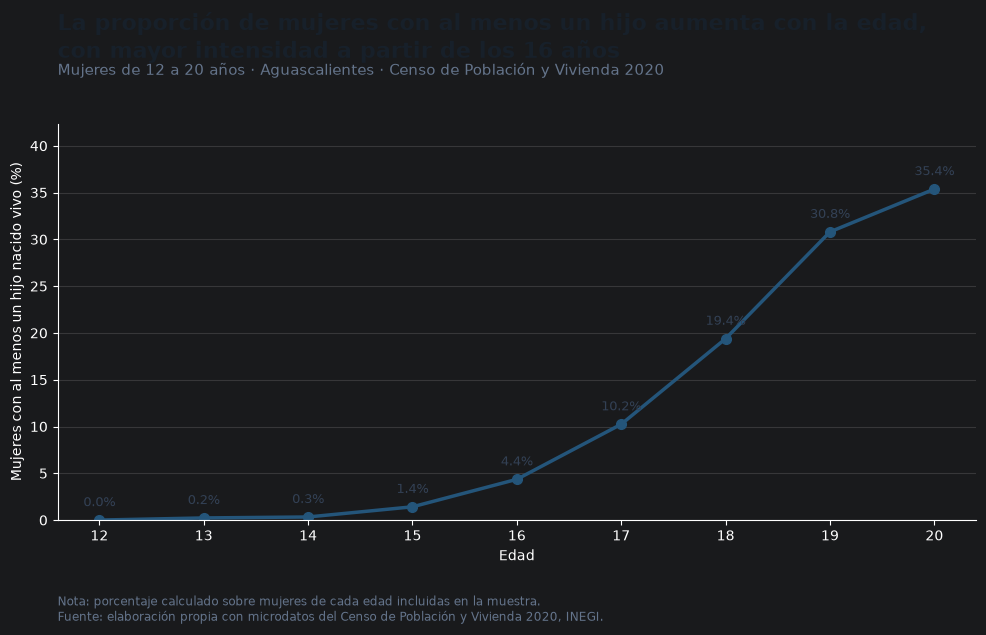

In [92]:
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.plot(tabla_fec["EDAD"], tabla_fec["PORCENTAJE"],
        marker="o", linewidth=2.5, markersize=7, color="#24557A")

for _, fila in tabla_fec.iterrows():
    ax.annotate(f'{fila["PORCENTAJE"]:.1f}%',
                (fila["EDAD"], fila["PORCENTAJE"]),
                xytext=(0, 10), textcoords="offset points",
                ha="center", fontsize=9, color="#334155")

fig.suptitle(
    "La proporción de mujeres con al menos un hijo aumenta con la edad,\n"
    "con mayor intensidad a partir de los 16 años",
    x=0.125, y=0.965, ha="left", fontsize=16, fontweight="bold", color="#17202A"
)
fig.text(0.125, 0.865,
         "Mujeres de 12 a 20 años · Aguascalientes · Censo de Población y Vivienda 2020",
         fontsize=10.5, color="#64748B")

ax.set_xlabel("Edad")
ax.set_ylabel("Mujeres con al menos un hijo nacido vivo (%)")
ax.set_xticks(tabla_fec["EDAD"])
ax.set_ylim(0, tabla_fec["PORCENTAJE"].max() + 7)
ax.grid(axis="y", alpha=0.20, linewidth=0.8)
ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(0.125, 0.025,
         "Nota: porcentaje calculado sobre mujeres de cada edad incluidas en la muestra.\n"
         "Fuente: elaboración propia con microdatos del Censo de Población y Vivienda 2020, INEGI.",
         fontsize=8.5, color="#64748B")
plt.subplots_adjust(left=0.125, right=0.96, top=0.79, bottom=0.18)
plt.show()


### 5.2 Visualización interactiva

El *hover* permite consultar edad, tamaño de muestra, número de mujeres con al menos un hijo y porcentaje, aportando detalle sin saturar la gráfica.


In [93]:
fig_fec = go.Figure()
fig_fec.add_trace(go.Scatter(
    x=tabla_fec["EDAD"], y=tabla_fec["PORCENTAJE"], mode="lines+markers",
    customdata=tabla_fec[["TOTAL_MUJERES", "MUJERES_CON_HIJO"]],
    hovertemplate=(
        "<b>Edad: %{x} años</b><br><br>"
        "Mujeres en la muestra: %{customdata[0]:,.0f}<br>"
        "Con al menos un hijo: %{customdata[1]:,.0f}<br>"
        "Porcentaje: %{y:.2f}%<extra></extra>"
    )
))
fig_fec.update_layout(
    title={"text":"Mujeres de 12 a 20 años con al menos un hijo nacido vivo","x":0.5},
    xaxis_title="Edad", yaxis_title="Porcentaje en la muestra (%)", hovermode="closest"
)
fig_fec.update_xaxes(tickmode="linear", dtick=1)
fig_fec.update_yaxes(rangemode="tozero")

from IPython.display import HTML, display
display(HTML(fig_fec.to_html(include_plotlyjs="cdn", full_html=False)))

# 6. Dificultades reportadas en edades de 0 a 5 años

Se examinan **caminar, bañarse y hablar**. Se conservan los códigos sustantivos 1 a 4: sin dificultad, poca dificultad, mucha dificultad y no puede hacerlo.


In [94]:
VARIABLES_DISCAPACIDAD = {
    "Caminar": "DIS_CAMINAR",
    "Bañarse": "DIS_BANARSE",
    "Hablar": "DIS_HABLAR"
}
ETIQUETAS_DIFICULTAD = {
    1: "No tiene dificultad",
    2: "Lo hace con poca dificultad",
    3: "Lo hace con mucha dificultad",
    4: "No puede hacerlo"
}

datos_dis = []
for actividad, variable in VARIABLES_DISCAPACIDAD.items():
    df[variable] = pd.to_numeric(df[variable], errors="coerce")
    temporal = df[(df["EDAD"].between(0,5)) & (df[variable].isin([1,2,3,4]))].copy()
    resumen = temporal.groupby(["EDAD", variable]).size().reset_index(name="FRECUENCIA")
    resumen["ACTIVIDAD"] = actividad
    resumen["CODIGO"] = resumen[variable]
    resumen["DIFICULTAD"] = resumen["CODIGO"].map(ETIQUETAS_DIFICULTAD)
    datos_dis.append(resumen[["EDAD","ACTIVIDAD","CODIGO","DIFICULTAD","FRECUENCIA"]])

tabla_dis = pd.concat(datos_dis, ignore_index=True)
tabla_dis.head(12)


,EDAD,ACTIVIDAD,CODIGO,DIFICULTAD,FRECUENCIA
0,0,Caminar,1,No tiene dificultad,1811
1,0,Caminar,2,Lo hace con poca dificultad,1
2,0,Caminar,3,Lo hace con mucha dificultad,1
3,0,Caminar,4,No puede hacerlo,25
4,1,Caminar,1,No tiene dificultad,1795
5,1,Caminar,2,Lo hace con poca dificultad,7
6,1,Caminar,3,Lo hace con mucha dificultad,2
7,1,Caminar,4,No puede hacerlo,6
8,2,Caminar,1,No tiene dificultad,1916
9,2,Caminar,2,Lo hace con poca dificultad,11


### 6.1 Interactividad por actividad

La visualización utiliza botones para alternar entre caminar, bañarse y hablar. El panel superior muestra los registros sin dificultad y el inferior distingue los distintos grados de dificultad.


In [95]:
fig_dis = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.12,
    row_heights=[0.38,0.62],
    subplot_titles=("Sin dificultad reportada","Grados de dificultad reportados")
)
actividades = list(VARIABLES_DISCAPACIDAD.keys())
trazas = {a: [] for a in actividades}

for actividad in actividades:
    da = tabla_dis[tabla_dis["ACTIVIDAD"] == actividad]
    sd = da[da["CODIGO"] == 1]
    fig_dis.add_trace(go.Scatter(
        x=sd["EDAD"], y=sd["FRECUENCIA"], mode="lines+markers",
        name="No tiene dificultad", visible=(actividad=="Caminar"),
        customdata=sd[["ACTIVIDAD","DIFICULTAD"]],
        hovertemplate="<b>%{customdata[0]}</b><br>Edad: %{x} años<br>%{customdata[1]}<br>Frecuencia: %{y:,.0f}<extra></extra>"
    ), row=1, col=1)
    trazas[actividad].append(len(fig_dis.data)-1)

    for codigo_d in [2,3,4]:
        cat = da[da["CODIGO"] == codigo_d]
        fig_dis.add_trace(go.Scatter(
            x=cat["EDAD"], y=cat["FRECUENCIA"], mode="lines+markers",
            name=ETIQUETAS_DIFICULTAD[codigo_d], visible=(actividad=="Caminar"),
            customdata=cat[["ACTIVIDAD","DIFICULTAD"]],
            hovertemplate="<b>%{customdata[0]}</b><br>Edad: %{x} años<br>%{customdata[1]}<br>Frecuencia: %{y:,.0f}<extra></extra>"
        ), row=2, col=1)
        trazas[actividad].append(len(fig_dis.data)-1)

botones = []
for actividad in actividades:
    visible = [False] * len(fig_dis.data)
    for i in trazas[actividad]:
        visible[i] = True
    botones.append(dict(label=actividad, method="update",
                        args=[{"visible":visible},
                              {"title":{"text":f"Dificultad reportada por edad: {actividad.lower()}","x":0.5}}]))

fig_dis.update_layout(
    title={"text":"Dificultad reportada por edad: caminar","x":0.5},
    updatemenus=[dict(type="buttons",direction="right",buttons=botones,x=0.5,xanchor="center",y=1.12)],
    height=720, hovermode="closest"
)
from IPython.display import HTML, display

display(
    HTML(
        fig_dis.to_html(
            include_plotlyjs="cdn",
            full_html=False
        )
    )
)


# 7. Análisis territorial

Se consideran las variables relacionadas con **ver, oír, caminar, recordar, bañarse, hablar y condición mental**. Se identifica alguna dificultad cuando al menos una variable presenta código 2, 3 o 4. Para el denominador se consideran registros con al menos una respuesta sustantiva entre 1 y 4.

El indicador se pondera mediante `FACTOR` y se resume por municipio.

> **Advertencia metodológica:** es un indicador exploratorio y **no corresponde a una estimación oficial de prevalencia de discapacidad**.


In [96]:
VARIABLES_DIFICULTAD = [
    "DIS_VER","DIS_OIR","DIS_CAMINAR","DIS_RECORDAR",
    "DIS_BANARSE","DIS_HABLAR","DIS_MENTAL"
]
for variable in VARIABLES_DIFICULTAD + ["MUN","FACTOR"]:
    df[variable] = pd.to_numeric(df[variable], errors="coerce")

respuestas_validas = df[VARIABLES_DIFICULTAD].isin([1,2,3,4]).any(axis=1)
alguna_dificultad = df[VARIABLES_DIFICULTAD].isin([2,3,4]).any(axis=1)

territorial = df[respuestas_validas & df["MUN"].notna() & df["FACTOR"].notna()].copy()
territorial["ALGUNA_DIFICULTAD"] = alguna_dificultad.loc[territorial.index]
territorial["DIFICULTAD_PONDERADA"] = territorial["FACTOR"] * territorial["ALGUNA_DIFICULTAD"].astype(int)

municipal = territorial.groupby("MUN").agg(
    N_MUESTRA=("MUN","size"),
    POBLACION_PONDERADA=("FACTOR","sum"),
    DIFICULTAD_PONDERADA=("DIFICULTAD_PONDERADA","sum")
).reset_index()

municipal["PORCENTAJE_PONDERADO"] = municipal["DIFICULTAD_PONDERADA"] / municipal["POBLACION_PONDERADA"] * 100
municipal["CVE_MUN"] = "01" + municipal["MUN"].astype(int).astype(str).str.zfill(3)
municipal


,MUN,N_MUESTRA,POBLACION_PONDERADA,DIFICULTAD_PONDERADA,PORCENTAJE_PONDERADO,CVE_MUN
0,1,17867,945309,153233,16.209832,01001
1,2,8094,51474,7845,15.240704,01002
2,3,8398,58155,11812,20.311237,01003
3,4,5794,16997,2981,17.538389,01004
4,5,9694,129835,21393,16.477067,01005
5,6,9305,47557,7874,16.556974,01006
6,7,10753,57269,9312,16.260106,01007
7,8,4541,9552,1276,13.358459,01008
8,9,7148,22461,3099,13.797249,01009
9,10,6233,20382,3441,16.882543,01010


## 7.1 Integración con el Marco Geoestadístico

La unión con la cartografía municipal se realiza mediante la clave geográfica municipal.


In [97]:
with zipfile.ZipFile(ARCHIVO_GEO, "r") as z:
    capas = [a for a in z.namelist() if a.lower().endswith(".shp") and "mun" in a.lower()]
if not capas:
    raise FileNotFoundError("No se encontró una capa municipal.")

municipios_geo = gpd.read_file(f"zip://{ARCHIVO_GEO}!{capas[0]}")

if "CVEGEO" in municipios_geo.columns:
    municipios_geo["CVE_MUN"] = municipios_geo["CVEGEO"].astype(str)
elif "CVE_ENT" in municipios_geo.columns and "CVE_MUN" in municipios_geo.columns:
    municipios_geo["CVE_MUN"] = municipios_geo["CVE_ENT"].astype(str) + municipios_geo["CVE_MUN"].astype(str)
else:
    raise KeyError("No fue posible identificar la clave municipal.")

mapa = municipios_geo.merge(municipal, on="CVE_MUN", how="left")
mapa["MUNICIPIO"] = mapa["NOMGEO"] if "NOMGEO" in mapa.columns else mapa["CVE_MUN"]

mapa[["CVE_MUN","MUNICIPIO","N_MUESTRA","POBLACION_PONDERADA","PORCENTAJE_PONDERADO"]]


,CVE_MUN,MUNICIPIO,N_MUESTRA,POBLACION_PONDERADA,PORCENTAJE_PONDERADO
0,01001,Aguascalientes,17867,945309,16.209832
1,01002,Asientos,8094,51474,15.240704
2,01003,Calvillo,8398,58155,20.311237
3,01004,Cosío,5794,16997,17.538389
4,01005,Jesús María,9694,129835,16.477067
5,01006,Pabellón de Arteaga,9305,47557,16.556974
6,01007,Rincón de Romos,10753,57269,16.260106
7,01008,San José de Gracia,4541,9552,13.358459
8,01009,Tepezalá,7148,22461,13.797249
9,01010,El Llano,6233,20382,16.882543


## 7.2 Mapa interactivo municipal

El mapa utiliza un rango cromático fijo para mantener una interpretación consistente. El *hover* identifica el municipio y la selección permite destacar espacialmente un caso sin perder el contexto territorial.


In [98]:
mapa_wgs84 = mapa.to_crs(epsg=4326)

fig_mapa = px.choropleth(
    mapa_wgs84, geojson=mapa_wgs84.__geo_interface__,
    locations="CVE_MUN", featureidkey="properties.CVE_MUN",
    color="PORCENTAJE_PONDERADO", range_color=(10,22),
    hover_name="MUNICIPIO",
    color_continuous_scale=[
        [0.00,"#c6dbef"],[0.25,"#9ecae1"],[0.50,"#6baed6"],
        [0.75,"#3182bd"],[1.00,"#08519c"]
    ]
)
fig_mapa.update_geos(fitbounds="locations", visible=False, projection_type="mercator")
fig_mapa.update_traces(
    selected=dict(marker=dict(opacity=1)),
    unselected=dict(marker=dict(opacity=0.35)),
    marker_line_width=1.0, marker_line_color="#5f6b76",
    hovertemplate="<b>%{hovertext}</b><extra></extra>"
)
fig_mapa.update_layout(
    title={"text":"<b>La presencia de dificultades reportadas varía entre los municipios de Aguascalientes</b><br><sup>Porcentaje ponderado de población con al menos una dificultad reportada</sup>","x":0.5},
    clickmode="event+select", height=650
)
display(
    HTML(
        fig_mapa.to_html(
            include_plotlyjs="cdn",
            full_html=False
        )
    )
)


# 8. Preparación de datos para Business Intelligence

Para Tableau se genera una tabla agregada municipal. Así, la capa de BI utiliza únicamente los indicadores necesarios y no los microdatos completos.

El tablero de Tableau incorpora comparación municipal, KPI global dinámico, filtro interactivo y *tooltips* personalizados.


In [99]:
datos_bi = mapa[[
    "CVE_MUN","MUNICIPIO","N_MUESTRA","POBLACION_PONDERADA",
    "DIFICULTAD_PONDERADA","PORCENTAJE_PONDERADO"
]].copy()

archivo_csv_municipal = BASE_DIR / "datos" / "indicador_municipal.csv"
datos_bi.to_csv(archivo_csv_municipal, index=False, encoding="utf-8-sig")
datos_bi


,CVE_MUN,MUNICIPIO,N_MUESTRA,POBLACION_PONDERADA,DIFICULTAD_PONDERADA,PORCENTAJE_PONDERADO
0,01001,Aguascalientes,17867,945309,153233,16.209832
1,01002,Asientos,8094,51474,7845,15.240704
2,01003,Calvillo,8398,58155,11812,20.311237
3,01004,Cosío,5794,16997,2981,17.538389
4,01005,Jesús María,9694,129835,21393,16.477067
5,01006,Pabellón de Arteaga,9305,47557,7874,16.556974
6,01007,Rincón de Romos,10753,57269,9312,16.260106
7,01008,San José de Gracia,4541,9552,1276,13.358459
8,01009,Tepezalá,7148,22461,3099,13.797249
9,01010,El Llano,6233,20382,3441,16.882543


# 9. Consideraciones metodológicas

1. Las visualizaciones tienen un propósito **exploratorio**.
2. Una combinación poco frecuente no se interpreta automáticamente como error.
3. La visualización de fecundidad presenta porcentajes dentro de la muestra analizada.
4. El indicador territorial utiliza `FACTOR`, pero su construcción es específica de este ejercicio y no debe presentarse como una estimación oficial de prevalencia de discapacidad.
5. Tableau utiliza una tabla municipal agregada para separar el procesamiento de microdatos de la capa de Business Intelligence.

## Productos

- `fecundidad_estatica.png`
- `fecundidad.html`
- `discapacidad.html`
- `territorio.html`
- `indicador_municipal.csv`
- tablero publicado en Tableau Public
- sitio web integrador


# 10. Reproducibilidad

Para reproducir el análisis:

1. Mantener la estructura de carpetas indicada al inicio.
2. Colocar `Personas01.CSV` y `01_aguascalientes.zip` en `datos/`.
3. Instalar las bibliotecas declaradas en `requirements.txt`.
4. Ejecutar las celdas en orden o utilizar `generar_visualizaciones.py` para reconstruir los productos finales.
5. Consultar `README.md` para las fuentes originales y las instrucciones de ejecución.

La separación entre datos, procesamiento, visualizaciones y productos de BI permite rastrear el origen de los resultados y repetir el procedimiento sin depender de rutas específicas del equipo de desarrollo.
